# Tarea 2 · Parte 1 – Del archivo escaneado al texto buscable

**Pregunta guía:** ¿podemos convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| Dato | Valor |
| :--- | :--- |
| Fecha de extracción | 25 de octubre de 2026 |
| Corpus A – Documentos | 25 páginas peruanas (8 impresas, 8 fotos de celular, 9 manuscritas) elegidas entre 35 candidatas (las otras 10 son reserva para reemplazar descartes), de **Wikimedia Commons** |
| Corpus B – Audio | 10 entrevistas en español grabadas en el Perú (**Wikimedia Commons**) + 12 clips y 1 entrevista simulada de español peruano leído (**OpenSLR 73**, Google) |
| Licencias | Dominio público, CC BY 2.0, CC BY-SA 3.0 y CC BY-SA 4.0 (detalle por archivo en `datos/fuentes.csv`) |
| OCR | PaddleOCR 3.7.0 sobre paddlepaddle 3.2.2, `lang="es"` (detector PP-OCRv5 server, reconocedor PP-OCRv6 medium), CPU |
| ASR | faster-whisper 1.2.1, modelo `small` en CPU (int8), `language="es"`, VAD Silero activado |
| Diarización | Huellas de voz WeSpeaker ResNet34 (pyannote 4.0.7) + agrupamiento jerárquico, con `voz.py` de la Sesión 13 |
| Recuperación | `descargar.py` baja todo de nuevo; los archivos originales van en `datos/raw/` y no se suben a GitHub |

**Cómo se corre:** los modelos tardan (unos 40 s por página en CPU), así que `procesar.py` guarda el resultado de cada archivo en `datos/raw/` apenas sale. Este notebook llama a esas mismas funciones: si el respaldo existe, lo lee; si no, corre el modelo.

In [1]:
import torch  # en Windows, torch se importa antes que paddle o choca una DLL

import hashlib
import importlib.metadata as metadatos
import re
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio

import procesar
import voz

# png además del gráfico interactivo: GitHub no muestra los gráficos de Plotly sin imagen
pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 80)

for paquete in ["paddleocr", "paddlepaddle", "faster-whisper", "pyannote.audio", "easyocr", "jiwer"]:
    print(f"{paquete:15} {metadatos.version(paquete)}")

paddleocr       3.7.0
paddlepaddle    3.2.2
faster-whisper  1.2.1
pyannote.audio  4.0.7
easyocr         1.7.2
jiwer           4.0.0


## 1. El corpus y sus licencias

`descargar.py` bajó cada archivo con un `User-Agent` que dice quién pide y una pausa de 1,5 s entre descargas. Guardó la licencia y el autor de cada uno en `datos/fuentes_crudas.csv`.

In [2]:
fuentes_crudas = pd.read_csv("datos/fuentes_crudas.csv")
fuentes_crudas["tipo"] = fuentes_crudas["tipo"].fillna("audio")
fuentes_crudas.groupby(["modalidad", "tipo", "licencia"]).size().rename("archivos").reset_index()

,modalidad,tipo,licencia,archivos
0,audio,audio,CC BY-SA 4.0,24
1,documento,foto,CC BY 2.0,1
2,documento,foto,CC BY 4.0,1
3,documento,foto,CC BY-SA 3.0,1
4,documento,foto,CC BY-SA 4.0,10
5,documento,impreso,Public domain,8
6,documento,manuscrito,CC BY-SA 3.0,3
7,documento,manuscrito,CC BY-SA 4.0,1
8,documento,manuscrito,CC0,1
9,documento,manuscrito,Public domain,9


El audio de quechua de Huaylas (`shansha_quechua`) no es parte del corpus en español: queda aparte para la bonificación con MMS en el notebook 02.

In [3]:
documentos = fuentes_crudas[fuentes_crudas["modalidad"] == "documento"].copy()
audios = fuentes_crudas[(fuentes_crudas["modalidad"] == "audio") & (fuentes_crudas["id"] != "shansha_quechua")].copy()
print(f"Documentos candidatos: {len(documentos)}   Audios candidatos: {len(audios)}")

Documentos candidatos: 35   Audios candidatos: 23


## 2. Limpieza: duplicados por hash

Dos archivos con el mismo hash SHA-256 son el mismo archivo aunque tengan otro nombre. Commons a veces tiene la misma foto subida dos veces.

In [4]:
def hash_de_archivo(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


documentos["hash"] = documentos["archivo"].apply(hash_de_archivo)
audios["hash"] = audios["archivo"].apply(hash_de_archivo)

duplicados_docs = documentos[documentos["hash"].duplicated()]
duplicados_audio = audios[audios["hash"].duplicated()]
print(f"Documentos duplicados: {len(duplicados_docs)}   Audios duplicados: {len(duplicados_audio)}")

documentos = documentos.drop_duplicates("hash")
audios = audios.drop_duplicates("hash")

Documentos duplicados: 0   Audios duplicados: 0


## 3. OCR con PaddleOCR

Configuración base, sin personalizar: idioma español, sin corrección de orientación ni de curvatura de página. El único preprocesamiento es reducir las fotos de celular a 2000 px en el lado mayor (vienen a 4000 px): el OCR tarda la mitad y lee igual.

Por cada documento queda en `datos/raw/documentos/ocr_paddle/` el JSON crudo (cada línea con su confianza) y el recorte de cada línea detectada.

In [5]:
resultados_ocr = []
for fila in documentos.itertuples():
    resultado = procesar.ocr(fila.archivo, motor="paddle")
    resultados_ocr.append({
        "id": fila.id,
        "texto_ocr_crudo": resultado["texto"],
        "lineas_ocr": len(resultado["lineas"]),
        "confianza_media": sum(resultado["confianzas"]) / max(len(resultado["confianzas"]), 1),
        "segundos_ocr": resultado["segundos"],
    })

ocr_paddle = pd.DataFrame(resultados_ocr)
documentos = documentos.merge(ocr_paddle, on="id")
documentos["caracteres_ocr"] = documentos["texto_ocr_crudo"].str.len()
documentos[["id", "tipo", "lineas_ocr", "caracteres_ocr", "confianza_media", "segundos_ocr"]].round(2)

,id,tipo,lineas_ocr,caracteres_ocr,confianza_media,segundos_ocr
0,doc_001,impreso,24,768,0.95,75.95
1,doc_002,impreso,32,1530,0.98,62.67
2,doc_003,impreso,34,1326,0.99,57.57
3,doc_004,impreso,39,2454,0.98,72.69
4,doc_005,impreso,37,2041,0.99,84.09
5,doc_006,impreso,41,2170,0.98,67.71
6,doc_007,impreso,44,1664,0.94,65.33
7,doc_008,impreso,30,1179,0.95,56.29
8,doc_009,foto,7,117,0.93,18.73
9,doc_010,foto,12,382,0.91,21.45


Así se ve lo que leyó en una placa fotografiada en la calle (las primeras líneas, con la confianza del modelo):

In [6]:
ejemplo = procesar.ocr("datos/raw/documentos/doc_016.jpg")
for linea, confianza in list(zip(ejemplo["lineas"], ejemplo["confianzas"]))[:8]:
    print(f"{confianza:.2f}  {linea}")

1.00  EN ESTA CASA DON JUAN LUIS
0.99  ROSPIGLIOSIYGOMEZ SANCHEZ
1.00  EL 25 DE MAYO DE 1911 DIO
1.00  INICIO AL MOVIMIENTO SCOUT
0.98  EN EL PERU
0.98  HOMENAJE DE LA FRATERNIDAD
1.00  BADEN POWELL AL
1.00  CONMEMORARSE EL 93


## 4. Limpieza: documentos ilegibles o que no son documentos

Criterios fijados **antes** de mirar los resultados de evaluación:

- **Ilegible:** el OCR saca menos de 40 caracteres, o su confianza media es menor a 0,60.
- **No es un documento:** revisión visual. `doc_015` resultó ser la foto de una conferencia con personas en primer plano: no es un documento y además muestra rostros, así que se descarta.

Los descartados se reemplazan con los documentos de reserva del mismo tipo hasta llegar a 8 impresos, 8 fotos y 9 manuscritos.

In [7]:
NO_SON_DOCUMENTOS = {"doc_015": "no es un documento: foto de un evento con personas"}

documentos["motivo_descarte"] = None
documentos.loc[documentos["caracteres_ocr"] < 40, "motivo_descarte"] = "ilegible: menos de 40 caracteres"
documentos.loc[documentos["confianza_media"] < 0.60, "motivo_descarte"] = "ilegible: confianza media < 0,60"
for id_doc, motivo in NO_SON_DOCUMENTOS.items():
    documentos.loc[documentos["id"] == id_doc, "motivo_descarte"] = motivo

descartados = documentos[documentos["motivo_descarte"].notna()]
descartados[["id", "tipo", "caracteres_ocr", "confianza_media", "motivo_descarte"]].round(2)

,id,tipo,caracteres_ocr,confianza_media,motivo_descarte
11,doc_012,foto,28,0.49,"ilegible: confianza media < 0,60"
14,doc_015,foto,337,0.95,no es un documento: foto de un evento con personas
17,doc_018,manuscrito,362,0.51,"ilegible: confianza media < 0,60"
20,doc_021,manuscrito,0,0.00,"ilegible: confianza media < 0,60"
23,doc_024,manuscrito,476,0.52,"ilegible: confianza media < 0,60"
25,doc_026,foto,17,0.73,ilegible: menos de 40 caracteres
34,doc_035,manuscrito,28,0.79,ilegible: menos de 40 caracteres


In [8]:
CUOTA = {"impreso": 8, "foto": 8, "manuscrito": 9}

validos = documentos[documentos["motivo_descarte"].isna()].sort_values("id")
partes = []
for tipo, cantidad in CUOTA.items():
    partes.append(validos[validos["tipo"] == tipo].head(cantidad))
corpus_documentos = pd.concat(partes)

reserva_sin_usar = validos[~validos["id"].isin(corpus_documentos["id"])]
print(f"Descartados: {len(descartados)}   Reserva sin usar: {list(reserva_sin_usar['id'])}")
print(corpus_documentos["tipo"].value_counts().to_string())

Descartados: 7   Reserva sin usar: ['doc_030', 'doc_031', 'doc_034']
tipo
manuscrito    9
impreso       8
foto          8


## 5. Transcripción con faster-whisper

Modelo `small` en CPU con VAD: el detector de voz Silero corta los silencios y la música antes de que lleguen a Whisper, que es donde Whisper inventa frases. `condition_on_previous_text=False` evita que un error se arrastre al siguiente tramo.

In [9]:
resultados_asr = []
for fila in audios.itertuples():
    resultado = procesar.transcribir(fila.archivo, modelo="small")
    resultados_asr.append({
        "id": fila.id,
        "duracion_seg": resultado["duracion_seg"],
        "segundos_proceso": resultado["segundos_proceso"],
        "segmentos": len(resultado["segmentos"]),
        "segundos_con_voz": sum(s["fin"] - s["inicio"] for s in resultado["segmentos"]),
    })

asr_small = pd.DataFrame(resultados_asr)
asr_small["factor_tiempo_real"] = asr_small["segundos_proceso"] / asr_small["duracion_seg"]
audios = audios.merge(asr_small, on="id")
print(f"{audios['duracion_seg'].sum() / 60:.1f} minutos de audio en {audios['segundos_proceso'].sum() / 60:.1f} minutos de proceso")
audios[["id", "duracion_seg", "segmentos", "segundos_con_voz", "factor_tiempo_real"]].round(2)

38.4 minutos de audio en 21.3 minutos de proceso


,id,duracion_seg,segmentos,segundos_con_voz,factor_tiempo_real
0,openslr_m01,41.51,4,34.57,0.11
1,openslr_m02,29.73,5,25.88,0.13
2,openslr_m03,26.15,4,21.03,0.13
3,openslr_m04,32.38,4,27.84,0.13
4,openslr_m05,28.03,4,24.50,0.94
5,openslr_m06,28.11,4,24.80,0.42
6,openslr_h01,21.54,3,20.29,0.22
7,openslr_h02,26.66,3,23.96,0.15
8,openslr_h03,24.10,2,20.31,0.13
9,openslr_h04,27.09,3,23.58,0.12


## 6. Limpieza: audios sin voz

Un audio se descarta si el VAD encuentra voz en menos del 20 % de su duración (música, ruido o silencio).

In [10]:
audios["proporcion_voz"] = audios["segundos_con_voz"] / audios["duracion_seg"]
audios["motivo_descarte"] = None
audios.loc[audios["proporcion_voz"] < 0.20, "motivo_descarte"] = "sin voz: menos del 20 % con habla"

audios_descartados = audios[audios["motivo_descarte"].notna()]
print(f"Audios descartados: {len(audios_descartados)}")
audios[["id", "duracion_seg", "proporcion_voz"]].sort_values("proporcion_voz").head(5).round(2)

Audios descartados: 0


,id,duracion_seg,proporcion_voz
2,openslr_m03,26.15,0.80
0,openslr_m01,41.51,0.83
8,openslr_h03,24.10,0.84
11,openslr_h06,29.65,0.84
3,openslr_m04,32.38,0.86


## 7. Diarización: quién habla cuándo

Cada segmento se convierte en una "huella de voz" (un vector de 256 números) y se agrupan las huellas parecidas. Como no sabemos cuántas personas hay en cada entrevista, el umbral de distancia (0,7, el valor por defecto de `voz.py`) decide cuándo dos voces son distintas.

Primero en la **entrevista simulada**, donde sabemos la verdad: una mujer y un hombre peruanos que se turnan.

In [11]:
simulada = procesar.diarizar("datos/raw/audio/entrevista_simulada.wav")
pd.DataFrame(simulada["segmentos"])[["inicio", "fin", "hablante", "texto"]]

,inicio,fin,hablante,texto
0,0.56,7.53,H1,¿A qué hora cierra el mercado de flores?
1,7.53,10.53,H2,La granizada destruyó toda plantación de lechuga.
2,10.53,19.59,H1,"Las tejas rojas del tejado no son de México, son de Texas."
3,19.59,28.16,H2,Ayer llovió mucho y llegué tarde a mi reunión.
4,28.16,38.35,H1,Usted está interesado en las olimpiadas o en el Mundial de Gimnasia que menc...
5,38.35,48.46,H2,¿Por qué dicen que la sal no es saludable?
6,48.46,52.46,H1,Mi sobrino me está volviendo loca con estas cosas de las redes sociales.
7,52.46,59.05,H2,¿Qué lugares románticos hay por aquí?


Las frases impares son de la mujer y las pares del hombre. Ahora se aplica lo mismo a todos los audios y se cuenta cuántos hablantes encuentra en cada uno. Además de la tabla, quedan los subtítulos `.srt` y la transcripción `.txt` de cada audio en `datos/raw/audio/diarizacion_small/`.

In [12]:
hablantes_por_audio = {}
texto_por_audio = {}
for fila in audios[audios["motivo_descarte"].isna()].itertuples():
    diarizado = procesar.diarizar(fila.archivo)
    hablantes = sorted({s["hablante"] for s in diarizado["segmentos"]})
    hablantes_por_audio[fila.id] = len(hablantes)
    # la marca de hablante solo tiene sentido si hay más de una voz
    if len(hablantes) > 1:
        turnos = [f"[HABLANTE_{s['hablante'][1:]}] {s['texto']}" for s in diarizado["segmentos"]]
    else:
        turnos = [s["texto"] for s in diarizado["segmentos"]]
    texto_por_audio[fila.id] = " ".join(turnos)

audios["n_hablantes"] = audios["id"].map(hablantes_por_audio)
audios["texto_asr_crudo"] = audios["id"].map(texto_por_audio)
audios[["id", "duracion_seg", "n_hablantes"]]

,id,duracion_seg,n_hablantes
0,openslr_m01,41.51,1
1,openslr_m02,29.73,1
2,openslr_m03,26.15,1
3,openslr_m04,32.38,1
4,openslr_m05,28.03,1
5,openslr_m06,28.11,1
6,openslr_h01,21.54,1
7,openslr_h02,26.66,1
8,openslr_h03,24.10,1
9,openslr_h04,27.09,1


## 8. Seudonimización

**Criterio:** se reemplazan los nombres de **personas privadas** que hablan o son mencionadas en las entrevistas (vendedoras, dirigentas, ciudadanos). Se mantienen los nombres de **figuras históricas y autoridades** que ya aparecen en monumentos y documentos públicos (un virrey, un presidente de 1937, Ricardo Palma, el alcalde que firma una placa).

Pasos:
1. Lista de nombres sacada de las descripciones de Commons y de una lectura de las transcripciones.
2. `voz.seudonimizar` los reemplaza con comparación difusa, para atrapar también las versiones mal escritas por el ASR ("Vásquez" / "Vázquez").
3. Reglas para números que podrían ser DNI (8 dígitos) o teléfonos (9 dígitos).
4. Revisión humana de lo que quedó: palabras con mayúscula que no están en el diccionario de lugares y cargos.

In [13]:
# la lista vive en procesar.py para que el notebook 02 seudonimice con las mismas reglas
print("Difusos (parecido >= 80):", procesar.REEMPLAZOS_DIFUSOS)
print("Exactos (parecido >= 95):", procesar.REEMPLAZOS_EXACTOS)

Difusos (parecido >= 80): {'Elena Durán': '[PERSONA_1]', 'Isabel Vásquez': '[PERSONA_2]', 'Elsa Barrientos': '[PERSONA_3]', 'Aurora Coronado': '[PERSONA_4]', 'Luz Mérida': '[PERSONA_5]', 'Luis Manuel Alvarado': '[PERSONA_6]', 'Durán': '[PERSONA_1]', 'Vásquez': '[PERSONA_2]', 'Barrientos': '[PERSONA_3]', 'Coronado': '[PERSONA_4]', 'Mérida': '[PERSONA_5]', 'Alvarado': '[PERSONA_6]', 'Jean Pierre Venegas': '[ENTREVISTADOR_2]', 'Alex Giles': '[PERSONA_7]', 'Carlos Ramírez': '[PERSONA_8]', 'Venegas': '[ENTREVISTADOR_2]', 'Giles': '[PERSONA_7]', 'Ramírez': '[PERSONA_8]'}
Exactos (parecido >= 95): {'Elena': '[PERSONA_1]', 'Isabel': '[PERSONA_2]', 'Elsa': '[PERSONA_3]', 'Aurora': '[PERSONA_4]', 'Luis': '[PERSONA_6]', 'Alex': '[PERSONA_7]', 'Carlos': '[PERSONA_8]', 'Edgar': '[PERSONA_9]', 'Jorge': '[ENTREVISTADOR]', 'Jean Pierre': '[ENTREVISTADOR_2]', 'Ampir': '[ENTREVISTADOR_2]'}


In [14]:
textos_asr, conteos_asr = [], []
for texto in audios["texto_asr_crudo"]:
    limpio, conteo = procesar.seudonimizar_texto(texto)
    textos_asr.append(limpio)
    conteos_asr.append(conteo)
audios["texto_asr"] = textos_asr
audios["entidades_reemplazadas"] = conteos_asr

textos_ocr, conteos_ocr = [], []
for texto in corpus_documentos["texto_ocr_crudo"]:
    limpio, conteo = procesar.seudonimizar_texto(texto, con_nombres=False)
    textos_ocr.append(limpio)
    conteos_ocr.append(conteo)
corpus_documentos["texto_ocr"] = textos_ocr
corpus_documentos["entidades_reemplazadas"] = conteos_ocr

print(f"Entidades reemplazadas en audio: {audios['entidades_reemplazadas'].sum()}")
print(f"Entidades reemplazadas en documentos: {corpus_documentos['entidades_reemplazadas'].sum()}")
audios.loc[audios["entidades_reemplazadas"] > 0, ["id", "entidades_reemplazadas"]]

Entidades reemplazadas en audio: 32
Entidades reemplazadas en documentos: 0


,id,entidades_reemplazadas
13,agustino_1,3
14,agustino_2,12
15,fenmucarinap_1,2
16,fenmucarinap_2,1
17,plaza_huancayo,3
19,entrevista_1,4
20,entrevista_2,2
21,entrevista_3,2
22,entrevista_4,3


Revisión humana: palabras con mayúscula inicial que siguen en las transcripciones y podrían ser nombres. Se leyeron una por una; son lugares, instituciones o inicios de oración.

In [15]:
palabras_mayuscula = []
for texto in audios["texto_asr"]:
    palabras_mayuscula += re.findall(r"(?<![.?!]\s)(?<!^)\b[A-ZÁÉÍÓÚÑ][a-záéíóúñ]{2,}\b", texto)
pd.Series(palabras_mayuscula).value_counts().head(40).to_dict()

{'Perú': 35,
 'Dios': 12,
 'Qué': 11,
 'Bueno': 11,
 'Muchas': 9,
 'San': 7,
 'Muy': 7,
 'Para': 6,
 'Cuáles': 5,
 'Por': 5,
 'Marcos': 5,
 'Porque': 5,
 'Pero': 5,
 'Estados': 5,
 'Unidos': 5,
 'Bien': 4,
 'Gracias': 4,
 'México': 3,
 'América': 3,
 'Cuál': 3,
 'Hay': 3,
 'Mundial': 3,
 'Universidad': 3,
 'Padula': 3,
 'Que': 3,
 'Nos': 3,
 'Congreso': 3,
 'Ahora': 3,
 'Mira': 3,
 'Lima': 3,
 'Como': 3,
 'Señor': 3,
 'Buenas': 3,
 'Las': 2,
 'Usted': 2,
 'Buenos': 2,
 'Nacional': 2,
 'Mayor': 2,
 'Quién': 2,
 'Martín': 2}

## 9. Análisis exploratorio

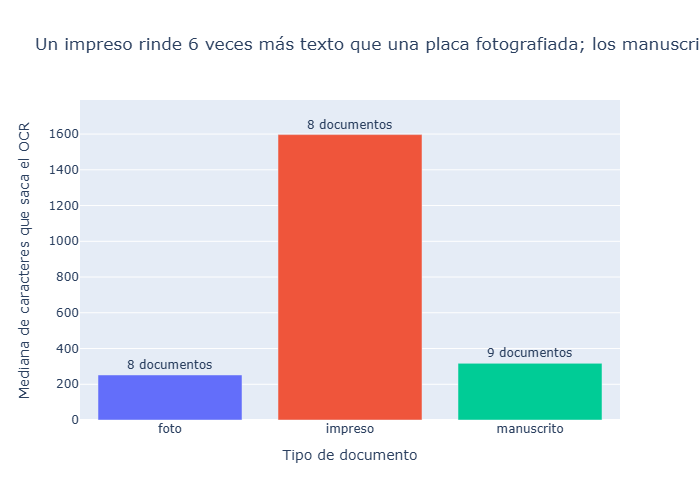

In [16]:
conteo_tipos = corpus_documentos.groupby("tipo").agg(documentos=("id", "count"), caracteres=("caracteres_ocr", "median")).reset_index()
medianas = conteo_tipos.set_index("tipo")["caracteres"]
titulo = (f"Un impreso rinde {medianas['impreso'] / medianas['foto']:.0f} veces más texto que una placa fotografiada; "
          f"los manuscritos quedan en medio")
fig = px.bar(conteo_tipos, x="tipo", y="caracteres", text="documentos", color="tipo", title=titulo,
             labels={"tipo": "Tipo de documento", "caracteres": "Mediana de caracteres que saca el OCR", "documentos": "Documentos"})
fig.update_traces(texttemplate="%{text} documentos", textposition="outside")
fig.update_layout(showlegend=False)
fig.show()

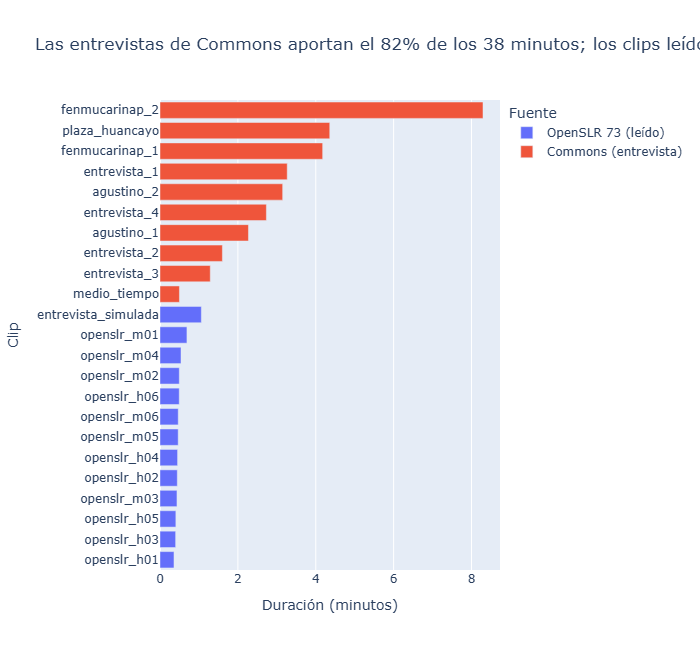

In [17]:
audios_validos = audios[audios["motivo_descarte"].isna()].copy()
audios_validos["fuente"] = audios_validos["fuente_url"].str.contains("openslr").map({True: "OpenSLR 73 (leído)", False: "Commons (entrevista)"})
audios_validos["minutos"] = audios_validos["duracion_seg"] / 60
minutos_por_fuente = audios_validos.groupby("fuente")["minutos"].sum()
titulo = (f"Las entrevistas de Commons aportan el {minutos_por_fuente['Commons (entrevista)'] / minutos_por_fuente.sum():.0%} "
          f"de los {minutos_por_fuente.sum():.0f} minutos; los clips leídos de OpenSLR duran menos de un minuto")
fig = px.bar(audios_validos.sort_values("duracion_seg"), x="minutos", y="id", color="fuente", orientation="h",
             title=titulo,
             labels={"minutos": "Duración (minutos)", "id": "Clip", "fuente": "Fuente"}, height=650)
fig.show()

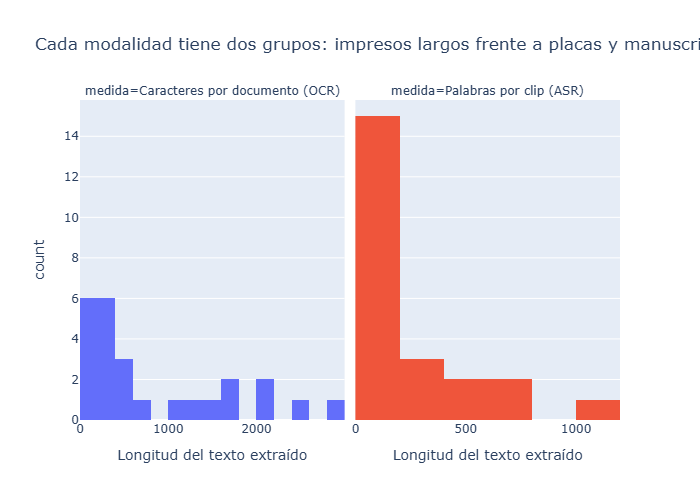

In [18]:
largos = pd.concat([
    pd.DataFrame({"longitud": corpus_documentos["caracteres_ocr"], "medida": "Caracteres por documento (OCR)"}),
    pd.DataFrame({"longitud": audios_validos["texto_asr"].str.split().str.len(), "medida": "Palabras por clip (ASR)"}),
])
fig = px.histogram(largos, x="longitud", facet_col="medida", nbins=15, color="medida",
                   title="Cada modalidad tiene dos grupos: impresos largos frente a placas y manuscritos cortos; entrevistas largas frente a frases leídas",
                   labels={"longitud": "Longitud del texto extraído", "count": "Archivos"})
fig.update_xaxes(matches=None)
fig.update_layout(showlegend=False)
fig.show()

## 10. Validación: los extremos

Si el histograma dice que los manuscritos dan poco texto, los documentos más cortos deberían ser manuscritos. Lo mismo con los clips: los más largos deberían ser entrevistas de Commons y los más cortos, frases leídas de OpenSLR.

In [19]:
columnas = ["id", "tipo", "caracteres_ocr", "texto_ocr"]
ordenados = corpus_documentos.sort_values("caracteres_ocr")
pd.concat([ordenados.tail(3), ordenados.head(3)])[columnas].assign(texto_ocr=lambda t: t["texto_ocr"].str[:70])

,id,tipo,caracteres_ocr,texto_ocr
5,doc_006,impreso,2170,—11—\nun k ilómetro se llega á un lugar llamado el Pedregal por estar c
3,doc_004,impreso,2454,"X.\nflor nace es semejante al del lirio en el tamaño: es muy verde,\nred"
16,doc_017,manuscrito,2826,"14\nNn que quas caxynoa, lesa lra ques to, enmedo.\n7 criatumas, mas al"
24,doc_025,manuscrito,80,300\n293\nPRIMER-CAPITVLODELASMOIAS\nDaCDAS\nLIeRn\nauasesa\nmamaona\nVAICO\nm
31,doc_032,manuscrito,101,390\nCOUQVISTA\nCORTALELACAVESAA\nATAGVALDAINGAVMATACVCHV\nmnrio atagualpa
8,doc_009,foto,117,"12.50\nDig\nEDIFICIO CONSTRUIDO POR\nJUVENAL\nMONGE Y CIA., CONSTRUCTORES."


In [20]:
columnas = ["id", "fuente", "duracion_seg", "texto_asr"]
ordenados = audios_validos.sort_values("duracion_seg")
pd.concat([ordenados.tail(3), ordenados.head(3)])[columnas].assign(texto_asr=lambda t: t["texto_asr"].str[:70])

,id,fuente,duracion_seg,texto_asr
15,fenmucarinap_1,Commons (entrevista),250.62,"[HABLANTE_1] Bueno, hola, estamos en los San Martín, entre Fritas Patr"
17,plaza_huancayo,Commons (entrevista),261.56,"[HABLANTE_1] Bien, hola, estamos aquí en la Plaza Mayor de Huancayo y"
16,fenmucarinap_2,Commons (entrevista),497.66,"[HABLANTE_1] ¿Qué esperamos? [HABLANTE_2] Bien, estamos en Plata San M"
6,openslr_h01,OpenSLR 73 (leído),21.54,¿Cuáles son las noticias más recientes del terremoto? Te recomiendo la
8,openslr_h03,OpenSLR 73 (leído),24.10,¿En qué piso está el departamento? ¿En cuántos juegos olímpicos ha par
10,openslr_h05,OpenSLR 73 (leído),24.44,Este fin de semana voy a ir al cine con mi esposa ¿Es verdad que usaro


## 11. Exportación

`texto_referencia` queda vacío: se completa en el notebook 02 con las transcripciones manuales de la muestra de evaluación.

In [21]:
corpus_documentos["modelo_ocr"] = "PaddleOCR 3.7 (lang=es, PP-OCRv5 server det + PP-OCRv6 medium rec, lado máx. 2000 px)"
corpus_documentos["fuente"] = "Wikimedia Commons (" + corpus_documentos["licencia"] + ")"
corpus_documentos["texto_referencia"] = None
tabla_documentos = corpus_documentos[["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia"]]
tabla_documentos.to_csv("datos/documentos.csv", index=False)

audios_validos["idioma"] = "es (español peruano según la fuente)"
audios_validos["modelo_asr"] = "faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker"
audios_validos["texto_referencia"] = None
tabla_audios = audios_validos[["id", "archivo", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia"]]
tabla_audios = tabla_audios.rename(columns={"archivo": "archivo_audio"})
tabla_audios.to_csv("datos/transcripciones.csv", index=False)

print("documentos.csv", tabla_documentos.shape)
print("transcripciones.csv", tabla_audios.shape, f"→ {tabla_audios['duracion_seg'].sum() / 60:.1f} minutos")

documentos.csv (25, 7)
transcripciones.csv (23, 8) → 38.4 minutos


In [22]:
tabla_documentos.head(5)

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Wikimedia Commons (Public domain),"EL LIBERTADOR BANON CASTILLA,\nGRAN MARISCAL DELOS EJERCITOS,\nCONDECORADO-C...","PaddleOCR 3.7 (lang=es, PP-OCRv5 server det + PP-OCRv6 medium rec, lado máx....",None
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Wikimedia Commons (Public domain),[4]\nTITULO III.\nGaRanTias Nacionales.\nARò. 5. Nadie puede arrogarse el tí...,"PaddleOCR 3.7 (lang=es, PP-OCRv5 server det + PP-OCRv6 medium rec, lado máx....",None
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Wikimedia Commons (Public domain),-9-\nIV.\nLa exposicion que hoy se abre en Lima poi\nlo mismo que es la prim...,"PaddleOCR 3.7 (lang=es, PP-OCRv5 server det + PP-OCRv6 medium rec, lado máx....",None
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Wikimedia Commons (Public domain),"X.\nflor nace es semejante al del lirio en el tamaño: es muy verde,\nredondo...","PaddleOCR 3.7 (lang=es, PP-OCRv5 server det + PP-OCRv6 medium rec, lado máx....",None
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Wikimedia Commons (Public domain),13\nÚLTIMAS TRADICIONES\nliterarias con Palma hicieron renacer mi deseo de p...,"PaddleOCR 3.7 (lang=es, PP-OCRv5 server det + PP-OCRv6 medium rec, lado máx....",None


In [23]:
tabla_audios.head(5)

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,openslr_m01,datos/raw/audio/openslr_m01.wav,41.51,es (español peruano según la fuente),"Hasta que no acabe es la tarea, no puede salir con tus amigos. El chicle se ...","faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",1,None
1,openslr_m02,datos/raw/audio/openslr_m02.wav,29.73,es (español peruano según la fuente),¿Cuál es el periódico más importante? Los corazones de pollo son una delicia...,"faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",1,None
2,openslr_m03,datos/raw/audio/openslr_m03.wav,26.15,es (español peruano según la fuente),Tú tienes que encargarte de todo eso. Quiero la computadora para estar en co...,"faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",1,None
3,openslr_m04,datos/raw/audio/openslr_m04.wav,32.38,es (español peruano según la fuente),La tienda de jabones y perfumes finos tienen regalos para el día de las madr...,"faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",1,None
4,openslr_m05,datos/raw/audio/openslr_m05.wav,28.03,es (español peruano según la fuente),No me gustan los bares donde hay poca gente. Los zapatos se estropearon con ...,"faster-whisper small (int8, CPU, VAD on) + diarización WeSpeaker",1,None


`fuentes.csv` lleva una fila por archivo usado (y por el audio en quechua de la bonificación). El enlace a Commons va por número de página (`?curid=`) para no repetir en la URL los nombres de personas que traen algunos títulos.

In [24]:
usados = pd.concat([corpus_documentos[["id"]], audios_validos[["id"]], pd.DataFrame({"id": ["shansha_quechua"]})])
fuentes = fuentes_crudas.merge(usados, on="id")
fuentes["acceso"] = fuentes["fuente_url"].str.contains("openslr").map({
    True: "descargar.py (lee del zip de OpenSLR 73 solo las frases usadas)",
    False: "descargar.py (API de Wikimedia Commons)"})
fuentes = fuentes[["id", "modalidad", "tipo", "fuente_url", "licencia", "acceso"]]
fuentes.to_csv("datos/fuentes.csv", index=False)
print(fuentes.shape)
fuentes.groupby(["modalidad", "licencia"]).size()

(49, 6)


modalidad  licencia     
audio      CC BY-SA 4.0     24
documento  CC BY-SA 3.0      3
           CC BY-SA 4.0      8
           Public domain    14
dtype: int64

## Qué hicimos

| Paso | Qué | Código clave |
| :--- | :--- | :--- |
| 1 | Bajar 35 documentos y 24 audios con licencia libre | `descargar.py` |
| 2 | Quitar duplicados por hash | `hashlib.sha256(...)` |
| 3 | OCR de cada página | `procesar.ocr(archivo, motor="paddle")` |
| 4 | Descartar ilegibles y lo que no es documento, y reemplazar con la reserva | `caracteres_ocr < 40`, `confianza_media < 0.60` |
| 5 | Transcribir con VAD | `procesar.transcribir(archivo, modelo="small")` |
| 6 | Descartar audios sin voz | `proporcion_voz < 0.20` |
| 7 | Separar hablantes y exportar SRT/TXT | `procesar.diarizar(archivo)` |
| 8 | Seudonimizar | `voz.seudonimizar(texto, REEMPLAZOS)` + reglas DNI/teléfono |
| 9 | Tres gráficos con Plotly | `px.bar`, `px.histogram` |
| 10 | Revisar los extremos | `sort_values(...).head(3)` / `.tail(3)` |
| 11 | Exportar los CSV | `to_csv("datos/documentos.csv")` |